# 08 · 真实公开表格：固定留出、原生二分类与无标签预测

本页使用 UCI Breast Cancer Wisconsin (Diagnostic) 的真实 M/B 诊断与30项既有数值测量，DOI：[10.24432/C5DW2B](https://doi.org/10.24432/C5DW2B)，[官方来源与CC-BY-4.0许可](https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic)。署名：Wolberg、Mangasarian、Street等，UCI，1993。

这些测量来自乳腺细针穿刺细胞核图像，**不是本包从NIfTI提取的radiomics，也不是现代多中心临床验证队列**。本教程不生成诊断、不使用sklearn下载/训练/评价，也不声称外部泛化或诊断效能。原始数据外置缓存；每次完整运行使用新的结果目录。


## 1. 明确环境、来源与本次输出目录

Notebook从头到尾直接调用公开API；先看Rust后端和已冻结协议。环境支持 `TUTORIAL_REPO_ROOT`、`TUTORIAL_RUN_ROOT`、`TUTORIAL_DATA_ROOT` 三个可选注入变量；普通交互运行会自动寻找完整仓库并创建新的临时输出目录。


In [1]:
from pathlib import Path
import sys, tempfile, json, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import ov_radiomics as rad

REPO = Path(TUTORIAL_REPO_ROOT).resolve() if 'TUTORIAL_REPO_ROOT' in globals() else next(
    (p for p in [Path.cwd(), *Path.cwd().parents]
     if (p / 'examples/real/public_tabular_source.json').is_file()), None)
if REPO is None:
    raise RuntimeError('请下载完整源码，并在仓库内启动Notebook。')
output = Path(TUTORIAL_RUN_ROOT) if 'TUTORIAL_RUN_ROOT' in globals() else Path(tempfile.mkdtemp(prefix='radiomics-public-tabular-'))
if 'TUTORIAL_RUN_ROOT' in globals():
    output.mkdir(parents=True, exist_ok=False)
facts_path = REPO / 'examples/real/public_tabular_source.json'
facts_bytes = facts_path.read_bytes()
facts = json.loads(facts_bytes)
protocol = facts['protocol']
assert facts['data_kind'] == 'real-public-tabular-no-clinical-validity'
assert rad.backend_info()['metrics_backend'] == 'rust'
from ov_radiomics._backend import resolve_backend
native_path = Path(resolve_backend('rust').__file__)
runtime = {'data_kind': facts['data_kind'], 'backend': rad.backend_info(),
           'python': sys.version, 'interpreter': sys.executable,
           'native_sha256': hashlib.sha256(native_path.read_bytes()).hexdigest(),
           'source_facts_sha256': hashlib.sha256(facts_bytes).hexdigest()}
(output / 'tutorial-runtime.json').write_text(json.dumps(runtime, indent=2), encoding='utf-8')
(output / 'source-facts.json').write_bytes(facts_bytes)
display(protocol)
print('新的输出目录:', output)


{'split_method': 'within each original diagnosis, sort by (SHA256(UTF8(namespace + source_id)), source_id); first floor(0.8*n_class) records train, rest test',
 'split_namespace': 'uci-wdbc-holdout-v1|',
 'training_fraction': 0.8,
 'group_identity': 'one source record ID per group, not independently verified clinical patient linkage',
 'task': 'binary',
 'classes': ['B', 'M'],
 'positive_label': 'M',
 'numeric_features': 'all 30 source measurements in declared order; no ID or diagnosis predictor',
 'categorical_features': [],
 'model': 'LR',
 'model_parameters': {'lambda': 0.1,
  'tolerance': 1e-10,
  'max_iterations': 5000},
 'scale': 'standard',
 'selection': None,
 'outer_cv': 3,
 'inner_cv': 2,
 'seed': 20261115,
 'n_jobs': 1,
 'fit_unit': 'sample',
 'scoring_unit': 'patient',
 'threshold': 0.5,
 'ci_method': None,
 'test_use': 'held-out evaluation only; never parameter/feature/threshold selection; remove diagnosis for saved-model prediction while retaining test cohort identity',
 

新的输出目录: E:\radiomics-build\public-tabular-v1\execution\08_public_tabular\artifacts


## 2. 下载/复用原始文件并核验SHA256

数据为CC-BY-4.0；保留数据署名、许可链接及改动说明，与软件MIT许可分开。官方URL的内容将来可能改变，因此每次读取都校验固定字节数和SHA；不同内容会报错，不改预期来绕过。

这里只导入标准库下载辅助函数，不运行另一份训练脚本。原始 `wdbc.data` 没有header，第一列为source ID，第二列是真实B/M诊断，后面30列按官方names定义排列。


In [2]:
cache = Path(TUTORIAL_DATA_ROOT) if 'TUTORIAL_DATA_ROOT' in globals() else Path.home() / 'radiomics-tutorial-data' / 'uci-wdbc'
sys.path.insert(0, str(REPO / 'examples/real'))
from download_public_tabular import fetch
fetch(cache)
for name, specification in facts['files'].items():
    assert (cache / name).stat().st_size == specification['bytes']
    assert hashlib.sha256((cache / name).read_bytes()).hexdigest() == specification['sha256']
features = facts['input']['feature_names']
raw = pd.read_csv(cache / 'wdbc.data', header=None,
                  names=['source_id', 'diagnosis'] + features,
                  dtype={'source_id': str, 'diagnosis': str})
assert raw.shape == (569, 32)
assert raw.source_id.notna().all() and raw.source_id.is_unique
assert set(raw.diagnosis) == {'B', 'M'}
assert np.isfinite(raw[features].to_numpy(dtype=float)).all()
display(raw.head())
display(raw.diagnosis.value_counts().rename('source records'))


Source: https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic DOI: 10.24432/C5DW2B
Dataset license: CC-BY-4.0 https://creativecommons.org/licenses/by/4.0/
Attribution: Wolberg, W., Mangasarian, O., Street, N., and Street, W. (1993). Breast Cancer Wisconsin (Diagnostic). UCI Machine Learning Repository. https://doi.org/10.24432/C5DW2B


,source_id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


B    357
M    212
Name: source records, dtype: int64

## 3. 在训练之前固定按ID的每类80/20划分

对每个真实诊断类，按 `SHA256('uci-wdbc-holdout-v1|' + source_id)` 再按source_id排序；前 `floor(0.8*n_class)` 进入train，其余test。整数取整使比例接近80/20。规则、模型和阈值在计算结果前声明，不为了AUC重挑seed或测试集。

原资料提供唯一记录ID，没有可验证的重复随访/患者链接。本例一source record对应一个本地group ID，交给患者分组API，但这**不证明569位独立患者或无隐藏受试者关联**。自己的多病灶/多切片数据必须改用真实共享patient_id，不能照抄一行一组。


In [3]:
data = raw.copy()
data['ID'] = 'wdbc:' + data.source_id
data['patient_id'] = data['ID']  # source-record grouping only; not proven clinical linkage
data['split_hash'] = data.source_id.map(lambda identity:
    hashlib.sha256((protocol['split_namespace'] + identity).encode('utf-8')).hexdigest())
data['group'] = 'test'
for label in protocol['classes']:
    ranked = data.loc[data.diagnosis == label].sort_values(['split_hash', 'source_id'])
    count = int(np.floor(protocol['training_fraction'] * len(ranked)))
    data.loc[ranked.index[:count], 'group'] = 'train'
assert not set(data.loc[data.group == 'train', 'patient_id']) & set(data.loc[data.group == 'test', 'patient_id'])
split_columns = ['source_id', 'ID', 'patient_id', 'diagnosis', 'split_hash', 'group']
data[split_columns].to_csv(output / 'split-assignments.csv', index=False)
data.to_csv(output / 'study.csv', index=False)
display(data.groupby(['group', 'diagnosis']).size().unstack(fill_value=0))
print('Predictors:', len(features), '; target: diagnosis; source/group IDs excluded')


diagnosis,B,M
group,,
test,72,43
train,285,169


Predictors: 30 ; target: diagnosis; source/group IDs excluded


## 4. 冻结原生Pipeline与患者组CV

使用全部30项既有特征、Standard scaling、LR的L2正则lambda=0.1、固定阈值0.5。没有单因素/稀疏筛选、没有多模型或参数网格搜索。填补/缩放仍由Rust在训练折拟合；test特征/诊断均不参与训练统计。只有一个候选时内层计划保留，但不会伪造候选选择分数或执行无意义调参。

外层3折、内层2折，固定seed。训练类顺序B/M，M为阳性。不要用测试标签选择特征或阈值。


In [4]:
plan = rad.SplitPlan.from_data(
    data, 'diagnosis', task='binary', classes=protocol['classes'],
    id_col='ID', patient_id='patient_id', split='group',
    outer_cv=protocol['outer_cv'], inner_cv=protocol['inner_cv'], seed=protocol['seed'])
result = rad.train_models(
    data, 'diagnosis', features, task='binary', classes=protocol['classes'],
    positive_label=protocol['positive_label'], models=[protocol['model']],
    model_params={protocol['model']: protocol['model_parameters']},
    scale=protocol['scale'], selector=None, categorical=[], backend='rust',
    split_plan=plan, id_col='ID', patient_id='patient_id', split='group',
    cv=protocol['outer_cv'], inner_cv=protocol['inner_cv'], random_state=protocol['seed'],
    fit_unit=protocol['fit_unit'], scoring_unit=protocol['scoring_unit'],
    threshold=protocol['threshold'], n_jobs=protocol['n_jobs'])
result.save(output / 'training')
result.models['LR'].save(output / 'model.rad')
display(result.cv_results)
print('SplitPlan SHA256:', result.split_plan.fingerprint)


,model,fold,score,auc
0,LR,0,0.995014,0.995014
1,LR,1,0.997368,0.997368
2,LR,2,0.994925,0.994925


SplitPlan SHA256: 44d8616dd2d1657a24ef0a897310bef1a333b47e42b1daa2a115b18fd8b38cfc


## 5. 分开查看OOF与固定留出结果

train最终预测是表观值；OOF由排除该组的外层模型生成，test则来自最终模型并保持独立留出身份。这里CI=None；AUC只是此数据、此固定划分的区分能力，不能解释成真实部署诊断概率或多中心临床泛化。

源ID分组一行一组，因此本页API中的patient评价单位等同源记录单位；真实患者级结论需要另外的链接证据。


,model,group,task,prediction_unit,n,prediction_type,positive_n,threshold,accuracy,auc,...,precision,recall,f1,brier,log_loss_eps1e15,average_precision,pr_auc_trapezoidal,ci_low,ci_high,status
0,LR,test,binary,patient,115,holdout,43,0.5,0.965217,0.988695,...,1.000000,0.906977,0.951220,0.033970,0.146972,0.989565,0.989497,NaN,NaN,evaluated
1,LR,train,binary,patient,454,apparent,169,0.5,0.964758,0.996657,...,0.993548,0.911243,0.950617,0.032206,0.133822,0.995062,0.995049,NaN,NaN,evaluated


,model,group,task,prediction_unit,n,prediction_type,positive_n,threshold,accuracy,auc,...,precision,recall,f1,brier,log_loss_eps1e15,average_precision,pr_auc_trapezoidal,ci_low,ci_high,status
0,Model,train,binary,patient,454,oof,169,0.5,0.962555,0.995931,...,0.993506,0.905325,0.947368,0.033673,0.136847,0.994079,0.994064,NaN,NaN,evaluated


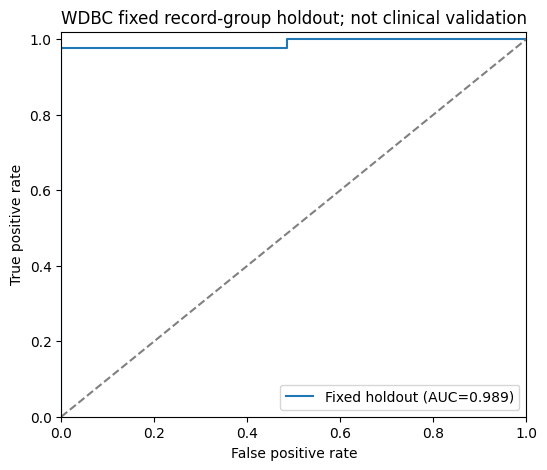

In [5]:
metrics = rad.evaluate(result, backend='rust', prediction_unit='patient', ci_method=None)
run = result.to_dict()['models'][0]
oof = rad.PredictionTable(run['oof'])
oof_metrics = rad.evaluate(oof, data=data, target='diagnosis', threshold=protocol['threshold'],
                           backend='rust', prediction_unit='patient', ci_method=None)
metrics.to_csv(output / 'cohort-metrics.csv', index=False)
oof_metrics.to_csv(output / 'oof-metrics.csv', index=False)
display(metrics)
display(oof_metrics)
held = rad.PredictionTable(run['predictions']).aggregate_patients().dataframe
held = held.loc[held.group == 'test'].merge(
    data[['patient_id', 'diagnosis']], on='patient_id', validate='one_to_one')
ax = rad.plot_roc((held.diagnosis == 'M').astype(int), {'Fixed holdout': held.probability},
                  backend='rust', title='WDBC fixed record-group holdout; not clinical validation')
ax.figure.savefig(output / 'holdout-roc.png', dpi=150, bbox_inches='tight')
plt.show()


## 6. 移除真实标签，再从.rad加载预测

这里用同一固定test数据演示无标签预测，**不把它改称独立外部队列**。删除diagnosis，保留原test和source/group身份。保存的填补/缩放/模型/阈值被复用，不对test重新拟合。若真正的新队列有不同样本/患者，准备显式external名称和相同特征定义。


In [6]:
unlabeled = data.loc[data.group == 'test'].drop(columns='diagnosis').copy()
unlabeled.to_csv(output / 'holdout-unlabeled.csv', index=False)
restored = rad.load_model(output / 'model.rad')
before = result.predict(unlabeled, model='LR')
after = restored.predict(unlabeled, id_col='ID', patient_id='patient_id', split='group')
assert before.to_dict() == after.to_dict()
after.dataframe.to_csv(output / 'holdout-loaded-predictions.csv', index=False)
display(after.dataframe.head())
print('保存/加载后无标签预测逐结构一致:', len(after.dataframe), 'records')


,ID,patient_id,slide_id,tile_id,model,group,fold,prediction_unit,prediction_type,training_source,probability::B,probability::M,probability
0,wdbc:84300903,wdbc:84300903,None,None,Model,test,None,sample,holdout,final:83a1f6b0556d9c7eb73f0e4cdca912b1de09f259...,0.005949,0.994051,0.994051
1,wdbc:84501001,wdbc:84501001,None,None,Model,test,None,sample,holdout,final:83a1f6b0556d9c7eb73f0e4cdca912b1de09f259...,0.026347,0.973653,0.973653
2,wdbc:845636,wdbc:845636,None,None,Model,test,None,sample,holdout,final:83a1f6b0556d9c7eb73f0e4cdca912b1de09f259...,0.472116,0.527884,0.527884
3,wdbc:846226,wdbc:846226,None,None,Model,test,None,sample,holdout,final:83a1f6b0556d9c7eb73f0e4cdca912b1de09f259...,0.021341,0.978659,0.978659
4,wdbc:84667401,wdbc:84667401,None,None,Model,test,None,sample,holdout,final:83a1f6b0556d9c7eb73f0e4cdca912b1de09f259...,0.113944,0.886056,0.886056


保存/加载后无标签预测逐结构一致: 115 records


## 7. 保存来源、改动和运行证据

保留原始数据署名、许可和每个源文件SHA；声明本教程只是列命名、按ID划分和原生模型使用示例。结果目录保留完整划分表、模型、OOF/队列预测和图，不仅是一张AUC截图。下面receipt是执行证据，不是新的Golden期望。

换成自己的CSV/Parquet时使用[明确列角色的文件工作流](../reference/user-guide/file-workflows.md)和[输入契约](../reference/user-guide/input-contracts.md)。自己的真实结局、重复患者链接、中心与采集时间必须重新声明；不要从本例生成伪患者或标签。


In [7]:
(output / 'DATA_NOTICE.md').write_text((cache / 'NOTICE.md').read_text(encoding='utf-8'), encoding='utf-8')
receipt = dict(
    schema='radiomics.public-tabular-tutorial.v1', data_kind=facts['data_kind'],
    status='passed', source_doi=facts['doi'], license=facts['license'],
    source_facts_sha256=runtime['source_facts_sha256'], protocol=protocol,
    input_sha256={name: hashlib.sha256((cache / name).read_bytes()).hexdigest() for name in facts['files']},
    runtime=runtime, records=len(data), predictors=len(features),
    cohorts={name: int(count) for name, count in data.group.value_counts().items()},
    classes=protocol['classes'], positive_label=protocol['positive_label'],
    split_plan_sha256=result.split_plan.fingerprint,
    split_table_sha256=hashlib.sha256((output / 'split-assignments.csv').read_bytes()).hexdigest(),
    save_load_predictions_exact=True, clinical_validity_claim=False,
    table_adaptation='Only column names, preserved source IDs, explicit source-record group IDs, and declared fixed split; no invented diagnosis',
    outputs={name: hashlib.sha256((output / name).read_bytes()).hexdigest() for name in
             ['model.rad', 'cohort-metrics.csv', 'oof-metrics.csv', 'holdout-roc.png', 'holdout-loaded-predictions.csv']})
(output / 'receipt.json').write_text(json.dumps(receipt, indent=2, ensure_ascii=False), encoding='utf-8')
print('结果文件:', [path.name for path in sorted(output.iterdir())])


结果文件: ['cohort-metrics.csv', 'DATA_NOTICE.md', 'holdout-loaded-predictions.csv', 'holdout-roc.png', 'holdout-unlabeled.csv', 'model.rad', 'oof-metrics.csv', 'receipt.json', 'source-facts.json', 'split-assignments.csv', 'study.csv', 'training', 'tutorial-runtime.json']
